# Dar_016 — Apollo 15 soil-mechanics reference experiments

**Questions:** What do the six tabulated penetration tests actually measure, how do geometry and source depth warnings affect comparison, and what can enter a future terrain/mobility evidence record?

R02: six historical Station 8 tests on **1 August 1971**, not a survey of our lunar-polar candidates. Original PDS4 labels, tables, headers and documentation are retained. [Implementation context](../../EDA_Notes.md).

In [3]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT / "darrel stuff/EDA/shared"), str(ROOT / "darrel stuff/EDA/Moon/Stage3_Requirements"),str(ROOT)]
DATA=ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from environment_workflow import LocalRun as Run
from research_p1_readers import pin_source
import research_p1_readers
import reference_eda
from reference_eda import iter_battery_cells,battery_record_summary,relative_capacity,soil_table

def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
def savefindings(run,values):
    run.path('findings.json').write_text(json.dumps(values,indent=2,default=str),encoding='utf-8');display(values)


## Design and safeguards
- Reuse the existing fixed-width PDS4 reader, selecting the file area belonging to the numeric table rather than its supplemental text header. Field lengths, row counts, units and `not_applicable_constant` are enforced. Raw source lines and source row order remain in exports.
- Preserve source LOAD, STRESS, PENETRATION_DEPTH and available CORRECTION fields. Convert N/cm² to kPa by multiplying by 10; do not reinterpret -9.99 as negative stress.
- Separate four cone runs from two plate runs. Nominal geometry is 3.22 cm² for the documented cone and 2.54×12.7 cm for the plate. Load/stress area is only a consistency diagnostic because stress is derived from force/area.
- Cone corrected depth is checked separately, not added to plate depths. Do not sort a loading/unloading sequence into a false monotonic curve. Raw lines preserve notes even if fixed-width note placement truncates text.
- Documentation warns about the depth-reference pad in runs 3–6 and trench collapse in run 6. Keep numeric records with these flags, not fabricated error bars or an implied six-site sample. UTC labels and ALSJ time estimates differ; no precise cross-experiment join is made.

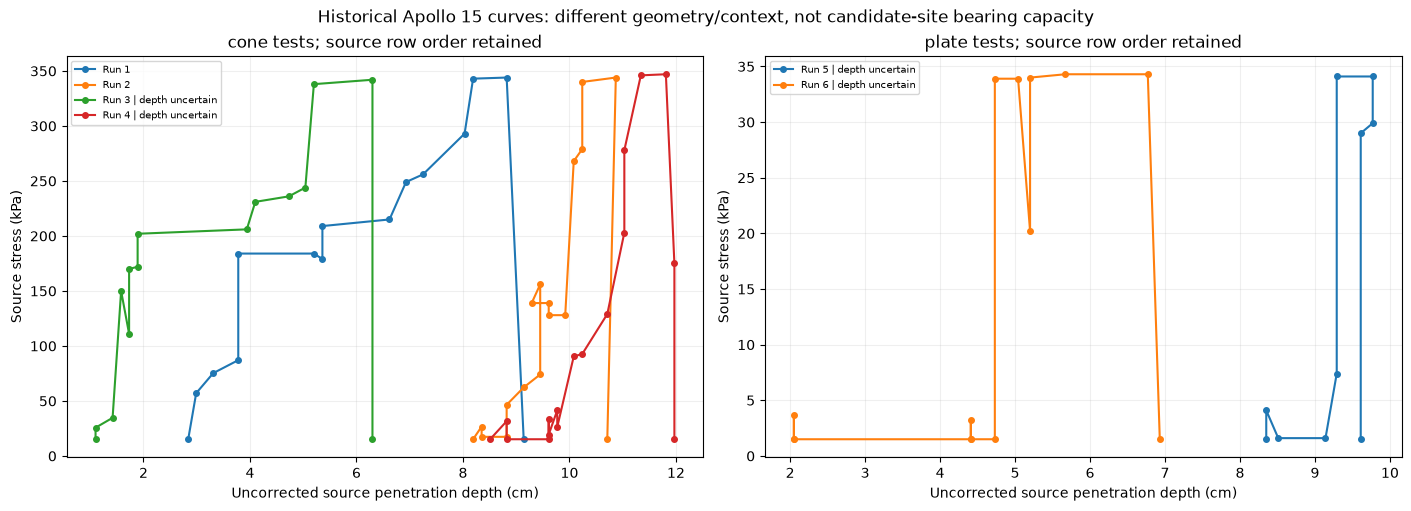

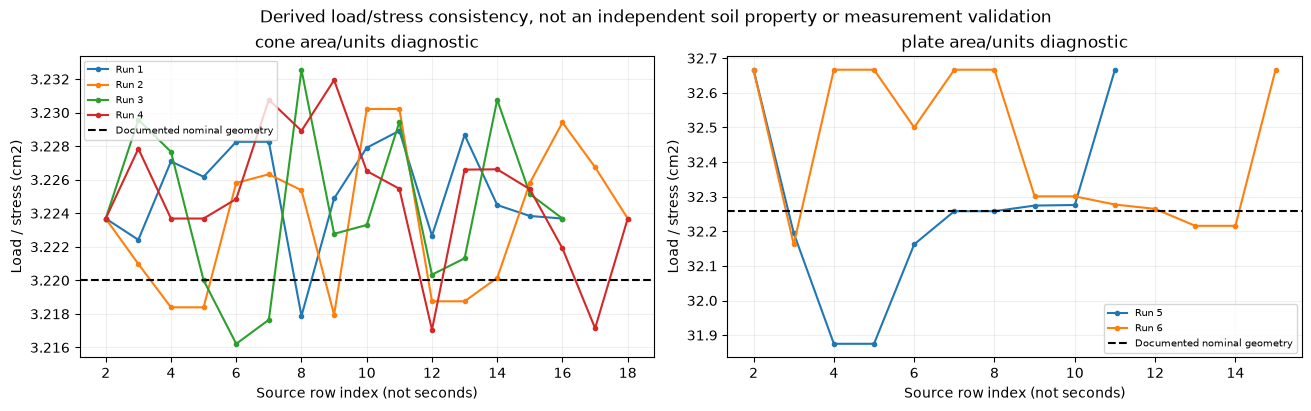

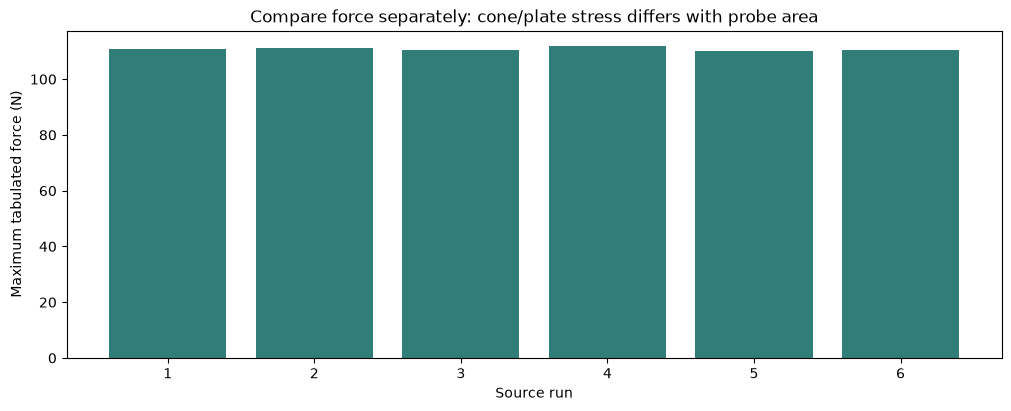

{'runs': 6,
 'source_records': 94,
 'not_applicable_stress_records': 6,
 'cone_runs': 4,
 'plate_runs': 2,
 'documented_depth_limited_runs': [3, 4, 5, 6],
 'documented_collapse_runs': [6],
 'cone_correction_range_cm': [3.749999999999999, 3.750000000000001],
 'maximum_force_range_N': [110.0, 111.8],
 'cone_maximum_stress_range_kPa': [342.0, 347.0],
 'plate_maximum_stress_range_kPa': [34.1, 34.300000000000004],
 'site_specific_equipment_checks': 'Unknown',
 'limits': ['Runs share one historical site; not six independent regions',
  'Runs 3-6 have documented depth-reference problems; run 6 has documented trench collapse',
  'Cone correction is not applied to plate records',
  'Numeric data are not wheel/soil response or allowable bearing capacity',
  'Label timestamps differ from ALSJ estimates by about six minutes; no precise cross-dataset alignment claimed',
  'Original tabulated records and source order retained; no fitted universal soil-strength law']}

,run,geometry,location_context,documented_depth_limitation,documented_trench_collapse,records,stress_not_applicable_records,maximum_force_N,maximum_stress_kPa,maximum_uncorrected_penetration_cm,median_implied_area_cm2,nominal_area_cm2,maximum_absolute_stress_unit_check_N_cm2
0,1,cone,adjacent north trench end,False,False,16,1,110.9,344.0,9.14,3.224880,3.220,0.078882
1,2,cone,trench bottom,False,False,18,1,111.0,344.0,10.87,3.223684,3.220,0.099379
2,3,cone,rover tracks,True,False,16,1,110.3,342.0,6.30,3.223684,3.220,0.113043
3,4,cone,adjacent rover tracks,True,False,18,1,111.8,347.0,11.97,3.225434,3.220,0.058385
4,5,plate,trench bottom,True,False,11,1,110.0,34.1,9.77,32.258065,32.258,0.002199
5,6,plate,outside trench; documented edge collapse,True,True,15,1,110.5,34.3,6.93,32.400442,32.258,0.004507


,run,count,min,max
0,1,16,3.75,3.75
1,2,18,3.75,3.75
2,3,16,3.75,3.75
3,4,18,3.75,3.75


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_016_apollo_soil_reference\20261109T145554487142Z_767579


In [4]:
labels=sorted((DATA/'reference/apollo15_soil').rglob('a15_smss_71_m016935_*.xml'))
if len(labels)!=6:raise ValueError('Expected the six R02 run labels; no verification-sample fallback')
docs={name:list((DATA/'reference/apollo15_soil').rglob(name)) for name in ['dataset_description.txt','dataset_description.xml','a15l_lsrp.txt','a15l_lsrp.xml']}
if any(len(paths)!=1 for paths in docs.values()):raise ValueError('Missing/ambiguous soil documentation')
with Run(ROOT,'analysis/dar_016_apollo_soil_reference',{'dataset':'R02','scope':'six Apollo 15 Station 8 tests, 1 August 1971',
    'decoding':'PDS4 field locations/types/constants; select table file area, retain supplemental headers',
    'stress_conversion':'1 N/cm2 = 10 kPa','operational_equipment_claim':False},'Moon/Terrain_And_Soil/Dar_016_apollo15_soil_reference.ipynb') as run:
    run.input(Path(reference_eda.__file__));run.input(Path(research_p1_readers.__file__))
    for paths in docs.values():pin_source(run,paths[0])
    frames,units=[],[]
    for label in labels:
        for path in [label,label.with_suffix('.tab'),label.with_suffix('.txt')]:pin_source(run,path)
        frame,meta=soil_table(label);frames.append(frame);units.extend(meta)
    data=pd.concat(frames,ignore_index=True)
    if data.duplicated(['run','source_row']).any():raise ValueError('Duplicate soil source rows')
    data.to_csv(run.path('decoded_soil_records.csv'),index=False)
    pd.DataFrame(units).to_csv(run.path('source_field_units.csv'),index=False)
    summary=data.groupby(['run','geometry','location_context','documented_depth_limitation','documented_trench_collapse'],dropna=False).agg(
        records=('source_row','size'),stress_not_applicable_records=('STRESS',lambda x:x.isna().sum()),
        maximum_force_N=('LOAD','max'),maximum_stress_kPa=('stress_kPa','max'),
        maximum_uncorrected_penetration_cm=('PENETRATION_DEPTH','max'),
        median_implied_area_cm2=('implied_area_cm2','median'),nominal_area_cm2=('nominal_area_cm2','first'),
        maximum_absolute_stress_unit_check_N_cm2=('stress_minus_force_over_area_N_cm2',lambda x:x.abs().max())).reset_index()
    summary.to_csv(run.path('run_summary.csv'),index=False)
    cone=data.loc[data.geometry.eq('cone')]
    correction=cone.groupby('run').cone_depth_correction_cm.agg(['count','min','max']).reset_index()
    correction.to_csv(run.path('cone_correction_check.csv'),index=False)
    fig,axes=plt.subplots(1,2,figsize=(14,5),layout='constrained')
    for ax,geometry in zip(axes,['cone','plate']):
        for number,part in data.loc[data.geometry.eq(geometry)].groupby('run'):
            note=' | depth uncertain' if part.documented_depth_limitation.iloc[0] else ''
            ax.plot(part.PENETRATION_DEPTH,part.stress_kPa,'o-',markersize=4,label=f'Run {number}'+note)
        ax.set(xlabel='Uncorrected source penetration depth (cm)',ylabel='Source stress (kPa)',title=geometry+' tests; source row order retained')
        ax.legend(fontsize=7);ax.grid(alpha=.2)
    fig.suptitle('Historical Apollo 15 curves: different geometry/context, not candidate-site bearing capacity')
    savefig(run,fig,'stress_penetration_by_geometry')
    fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
    for ax,geometry in zip(axes,['cone','plate']):
        part=data.loc[data.geometry.eq(geometry)]
        for number,group in part.groupby('run'):ax.plot(group.source_row,group.implied_area_cm2,'o-',markersize=3,label=f'Run {number}')
        ax.axhline(part.nominal_area_cm2.iloc[0],ls='--',color='black',label='Documented nominal geometry')
        ax.set(xlabel='Source row index (not seconds)',ylabel='Load / stress (cm2)',title=geometry+' area/units diagnostic')
        ax.legend(fontsize=7);ax.grid(alpha=.2)
    fig.suptitle('Derived load/stress consistency, not an independent soil property or measurement validation')
    savefig(run,fig,'area_unit_consistency')
    fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
    ax.bar(summary.run,summary.maximum_force_N,color='#317e78')
    ax.set(xlabel='Source run',ylabel='Maximum tabulated force (N)',title='Compare force separately: cone/plate stress differs with probe area')
    savefig(run,fig,'maximum_force_by_run')
    handoff=summary.copy();handoff['evidence_type']='historical Apollo 15 experiment; non-polar'
    handoff['candidate_region_match']='Not established';handoff['mobility_constraint_status']='Unknown'
    handoff['allowable_bearing_pressure_kPa']=np.nan;handoff['wheel_slip_or_sinkage_prediction']=np.nan
    handoff.to_csv(run.path('algorithm_reference_features.csv'),index=False)
    savefindings(run,{'runs':int(data.run.nunique()),'source_records':len(data),
        'not_applicable_stress_records':int(data.STRESS.isna().sum()),
        'cone_runs':int(cone.run.nunique()),'plate_runs':int(data.loc[data.geometry.eq('plate'),'run'].nunique()),
        'documented_depth_limited_runs':sorted(data.loc[data.documented_depth_limitation,'run'].unique().tolist()),
        'documented_collapse_runs':sorted(data.loc[data.documented_trench_collapse,'run'].unique().tolist()),
        'cone_correction_range_cm':[float(cone.cone_depth_correction_cm.min()),float(cone.cone_depth_correction_cm.max())],
        'maximum_force_range_N':[float(summary.maximum_force_N.min()),float(summary.maximum_force_N.max())],
        'cone_maximum_stress_range_kPa':[float(summary.loc[summary.geometry.eq('cone'),'maximum_stress_kPa'].min()),float(summary.loc[summary.geometry.eq('cone'),'maximum_stress_kPa'].max())],
        'plate_maximum_stress_range_kPa':[float(summary.loc[summary.geometry.eq('plate'),'maximum_stress_kPa'].min()),float(summary.loc[summary.geometry.eq('plate'),'maximum_stress_kPa'].max())],
        'site_specific_equipment_checks':'Unknown','limits':['Runs share one historical site; not six independent regions',
            'Runs 3-6 have documented depth-reference problems; run 6 has documented trench collapse',
            'Cone correction is not applied to plate records','Numeric data are not wheel/soil response or allowable bearing capacity',
            'Label timestamps differ from ALSJ estimates by about six minutes; no precise cross-dataset alignment claimed',
            'Original tabulated records and source order retained; no fitted universal soil-strength law']})
    display(summary);display(correction)
OUT=run.directory;print('Completed:',OUT)


## Implementation handoff
The exported run/geometry/context/depth-quality table can serve as a **historical reference or model-test case**. It cannot assign allowable polar bearing pressure, wheel slip, sinkage, foundation safety or a rover slope limit. Those need suitable local soil parameters, wheel/foot/loading geometry and validated response data. Carry the evidence limitations into Stage 3; do not train polar hazard labels from these six tests.